# Sup. Figs. 5-6: gene set size

EnrichMap with the null model (default since 0.3.0) and with smoothing only on the pyramidal layer and
striatum signatures of eight sizes (n = 2 to 500; the largest striatum set has 434 genes). Panels: 5a maps, 5b-c Moran's I
and Geary's C, 5d variograms, 5e AUROC, AUPRC and F1 (oracle and threshold rules), 6a-d cross-Moran and Spearman
correlation with the n = 50 score, 6e MSigDB gene set sizes. Source data are saved as CSV next to each figure.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import enrichmap as em
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from esda.moran import Moran
from esda.geary import Geary
from libpysal.weights import KNN
from libpysal.weights.spatial_lag import lag_spatial
from scipy.spatial.distance import pdist
from scipy.stats import pearsonr, spearmanr
from skgstat import Variogram
from sklearn.metrics import f1_score, precision_score, recall_score

In [3]:
sc.set_figure_params(frameon=False, fontsize=6)
sc.settings._vector_friendly = False
plt.rcParams["axes.grid"] = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)

# processed data directory
processed_data = project_dir + "processed_data/"

# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)

In [5]:
from helpers import (
    format_benchmark_metric_axis,
    set_box_ratio,
    gss_bar_panel,
    gss_draw_cross_moran,
    gss_draw_spearman,
    gss_draw_variograms,
    gss_fetch_msigdb,
    gss_fixed_rules_axis,
    gss_grouped_bars,
    gss_label_line_ends,
    gss_log10_p,
    gss_method_legend,
    gss_msigdb_gene_set_sizes,
    gss_otsu_threshold,
    gss_pair_panel,
    gss_paired_block_bootstrap,
    gss_parse_msigdb,
    gss_plot_summary,
    gss_size_ticks,
    gss_spatial_folds,
    gss_topk_calls,
    gss_threshold_rule_bootstrap,
    gss_wide_auc,
)

In [6]:
colours = {
    "EnrichMap (null)": "#2f0bdf",
}
spot_size = 20

In [7]:
# 1. Load data and signatures
adata = sq.datasets.visium_hne_adata()
adata.layers["counts"] = adata.raw.X.copy()
adata.X = adata.layers["counts"].copy()

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["log1p_norm"] = adata.X.copy()

cell_type_1 = "Pyramidal_layer"
cell_type_2 = "Striatum"

with open(project_dir + f"{cell_type_1}_signatures.pkl", "rb") as f:
    signature_dict_pyramidal = pickle.load(f)
with open(project_dir + f"{cell_type_2}_signatures.pkl", "rb") as f:
    signature_dict_cortex = pickle.load(f)

signature_dicts = {cell_type_1: signature_dict_pyramidal, cell_type_2: signature_dict_cortex}
regions = [cell_type_1, cell_type_2]
sizes = {ct: [int(k.split("_top")[1]) for k in signature_dicts[ct]] for ct in regions}

coords = adata.obsm["spatial"].astype(np.float64)
labels = {ct: (adata.obs["cluster"] == ct).values.astype(int) for ct in regions}
prevalence = {ct: labels[ct].mean() for ct in regions}

In [8]:
# 2. EnrichMap: null model (default) and smoothing-only for every gene set size
variants = {
    "null": dict(null_model=True, correct_spatial_covariates=False, compute_q_vals=True),
}

for ct, signature_dict in signature_dicts.items():
    for name, genes in signature_dict.items():
        for variant, kwargs in variants.items():
            em.tl.score(
                adata,
                gene_set=genes,
                score_key=f"{name}_{variant}",
                n_neighbors=6,
                smoothing=True,
                **kwargs,
            )

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_top2_null: 2/2 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_top2_null: 2/2 genes found: 100%|██████████| 1/1 [00:00<00:00, 10.07it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_top5_null: 5/5 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_top5_null: 5/5 genes found: 100%|██████████| 1/1 [00:00<00:00, 10.19it/s]

... (51 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum_top434_null: 434/434 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum_top434_null: 434/434 genes found: 100%|██████████| 1/1 [00:00<00:00,  7.01it/s]

Scoring Striatum_top434_null: 434/434 genes found: 100%|██████████| 1/1 [00:00<00:00,  6.94it/s]

In [9]:
# 3. Score column of each method
method_keys = {
    "EnrichMap (null)": "{name}_null_score",
#    "EnrichMap (smoothing-only)": "{name}_smooth_score",
}
methods = list(method_keys)

# scores[ct][method][size]: one value per spot; null-model p-values for the threshold rules
scores = {
    ct: {
        m: {n: adata.obs[k.format(name=f"{ct}_top{n}")].values.astype(np.float64) for n in sizes[ct]}
        for m, k in method_keys.items()
    }
    for ct in regions
}
p_empirical = {
    ct: {n: adata.uns["null_model"][f"{ct}_top{n}_null"]["p_empirical"] for n in sizes[ct]} for ct in regions
}


In [10]:
# score range per map; null model: fraction of spots with z > 1.96 (all, in the region, outside) and p_empirical <= 0.05
summary_rows = []
for ct in regions:
    y = labels[ct]
    for m in methods:
        for n in sizes[ct]:
            s = scores[ct][m][n]
            null = m == "EnrichMap (null)"
            summary_rows.append({
                "region": ct,
                "method": m,
                "gene set size": n,
                "min": s.min(),
                "median": np.median(s),
                "max": s.max(),
                "fraction > 0": np.mean(s > 0),
                "fraction > 1.96": np.mean(s > 1.96) if null else np.nan,
                "fraction p_empirical <= 0.05": np.mean(p_empirical[ct][n] <= 0.05) if null else np.nan,
                "fraction > 1.96 in region": np.mean(s[y == 1] > 1.96) if null else np.nan,
                "fraction > 1.96 outside region": np.mean(s[y == 0] > 1.96) if null else np.nan,
            })
score_summary = pd.DataFrame(summary_rows)
print(score_summary.round(3).to_string(index=False))

         region           method  gene set size     min  median     max  fraction > 0  fraction > 1.96  fraction p_empirical <= 0.05  fraction > 1.96 in region  fraction > 1.96 outside region
Pyramidal_layer EnrichMap (null)              2  -1.291  -0.635  21.915         0.233            0.068                         0.065                      1.000                           0.053
Pyramidal_layer EnrichMap (null)              5  -1.744  -0.751  25.584         0.222            0.073                         0.074                      1.000                           0.058
Pyramidal_layer EnrichMap (null)             10  -2.740  -1.103  27.005         0.190            0.089                         0.091                      1.000                           0.074
Pyramidal_layer EnrichMap (null)             20  -3.062  -1.238  34.450         0.205            0.108                         0.112                      1.000                           0.094
Pyramidal_layer EnrichMap (null)        

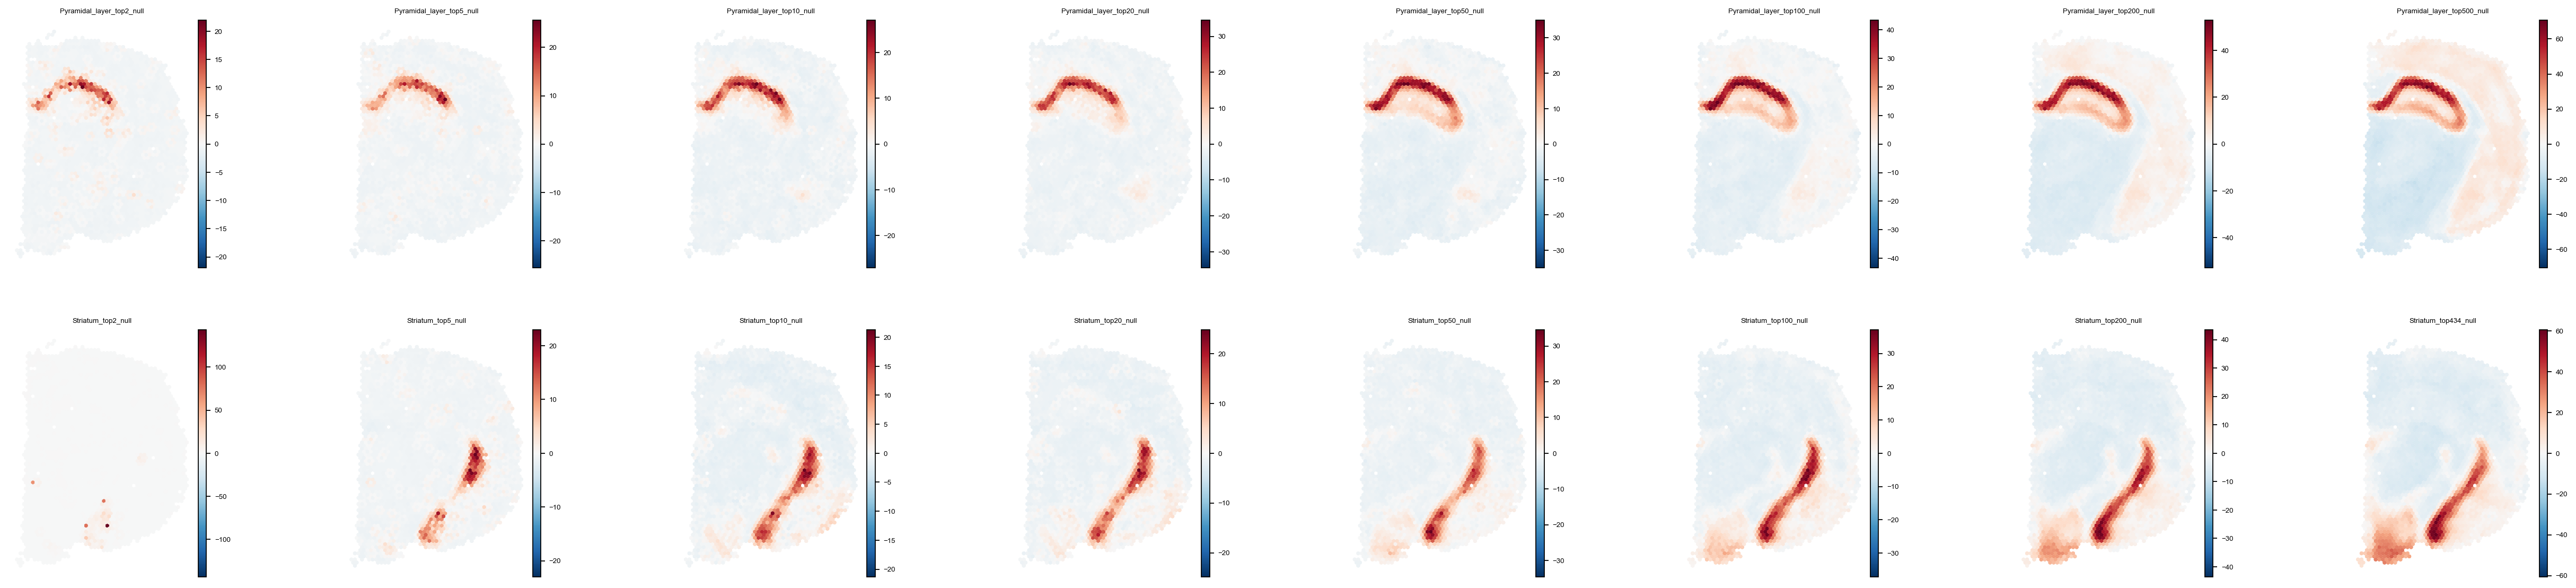

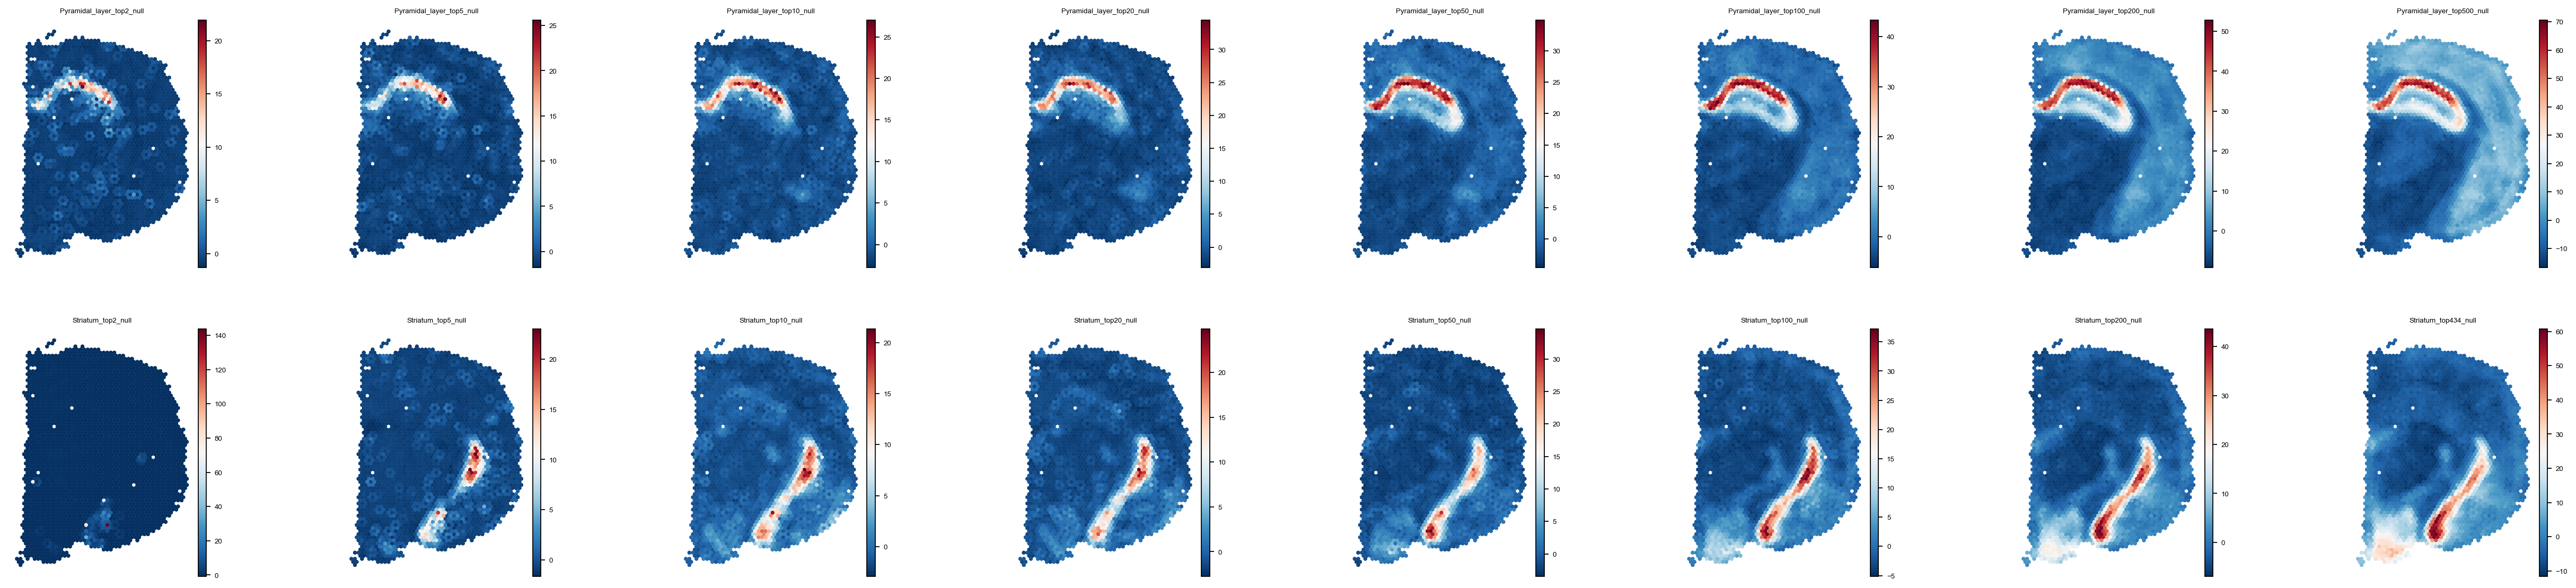

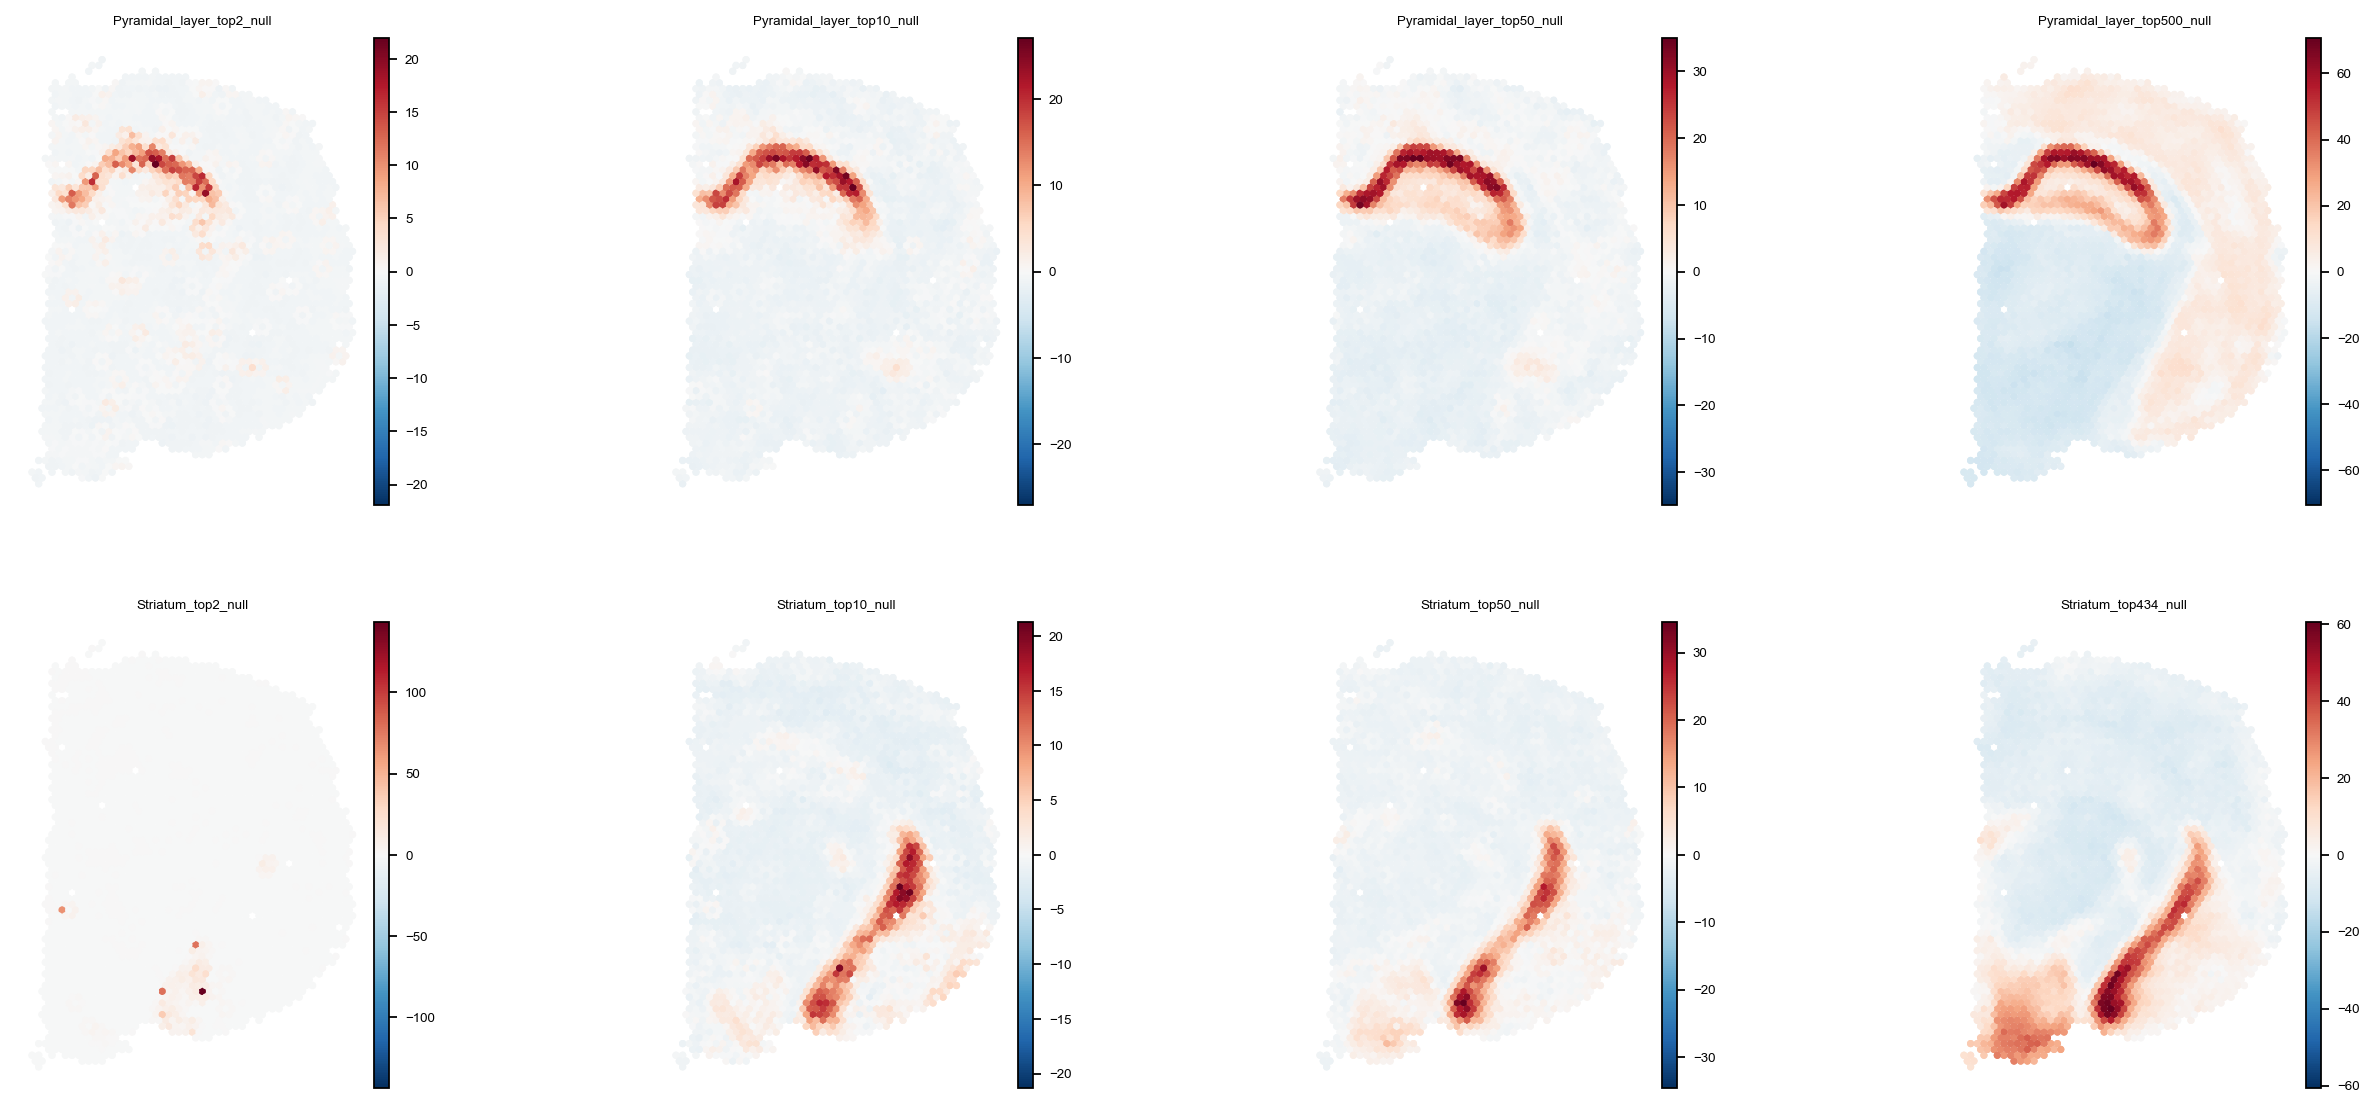

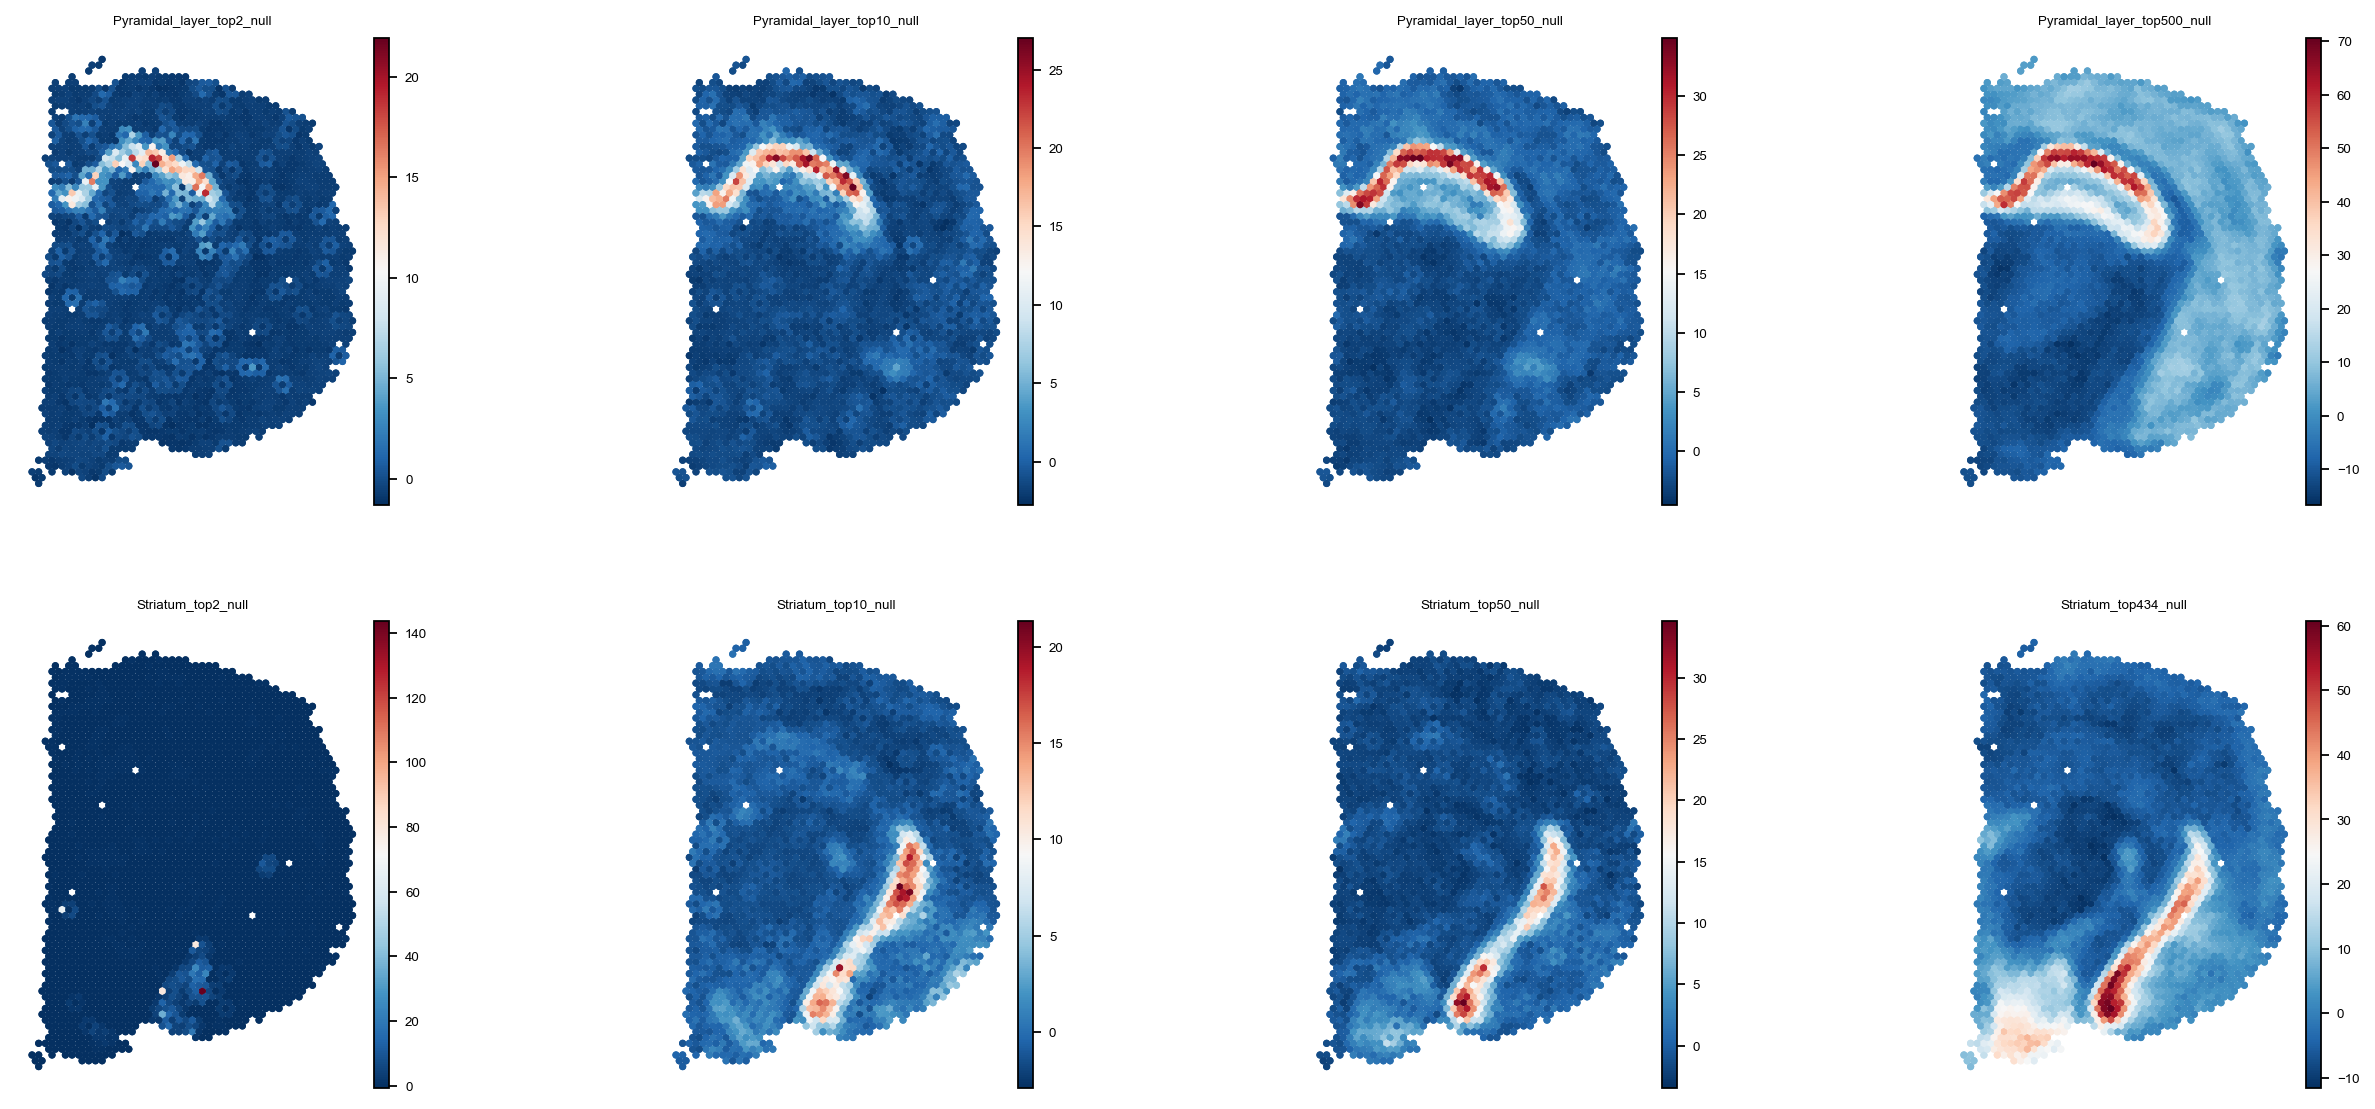

In [11]:
# 4. Sup. Fig. 5a: score maps of all eight sizes (full) and of n = 2, 10, 50 and the largest set, centred and uncentred
for stem, idx in [("REV_SupFig5_6_7_S5a_score_maps_full", range(8)), ("REV_SupFig5_6_7_S5a_score_maps", [0, 2, 4, 7])]:
    keys = [method_keys[m].format(name=f"{ct}_top{sizes[ct][i]}") for ct in regions for m in methods for i in idx]
    for vcenter, tag in ((0, "centred"), (None, "uncentred")):
        em.pl.spatial_enrichmap(
            adata, score_key=keys, vcenter=vcenter, ncols=len(idx),
            save="ExtendedDataFig4c_score_maps.pdf" if stem.endswith("_full") and tag == "centred" else f"{stem}_{tag}.pdf",
            shape=None,
            size=spot_size,
        )
    maps = adata.obs[["cluster"] + keys].copy()
    maps.insert(0, "y", coords[:, 1])
    maps.insert(0, "x", coords[:, 0])
    if stem.endswith("_full"):
        maps.to_csv(source_dir + "ExtendedDataFig4c_score_maps.csv")

In [12]:
# 5. Sup. Fig. 5b-c: Moran's I and Geary's C (em.tl.compute_spatial_metrics, as em.pl.spatial_metrics)
summary_rows = []
for ct in regions:
    for m, k in method_keys.items():
        for n in sizes[ct]:
            key = k.format(name=f"{ct}_top{n}")
            metrics, W = em.tl.compute_spatial_metrics(adata, score_key=key, n_neighbors=6)
            values = adata.obs[key].values.astype(np.float64)
            summary_rows.append({
                "region": ct,
                "method": m,
                "gene set size": n,
                "Moran's I": metrics["Moran's I"],
                "Moran's I z (normal)": Moran(values, W, permutations=0).z_norm,
                "Geary's C": metrics["Geary's C"],
                "Geary's C z (normal)": Geary(values, W, permutations=0).z_norm,
            })
autocorr = pd.DataFrame(summary_rows)
print(
    autocorr.pivot_table(index=["region", "gene set size"], columns="method", values=["Moran's I", "Geary's C"])
    .round(4).to_string()
)

                                     Geary's C        Moran's I
method                        EnrichMap (null) EnrichMap (null)
region          gene set size                                  
Pyramidal_layer 2                       0.2209           0.7522
                5                       0.1647           0.8289
                10                      0.1151           0.8804
                20                      0.1136           0.8826
                50                      0.0959           0.8985
                100                     0.0965           0.8955
                200                     0.0845           0.9089
                500                     0.0775           0.9169
Striatum        2                       0.8879           0.2082
                5                       0.1469           0.8596
                10                      0.0982           0.8991
                20                      0.1119           0.8829
                50                      

In [13]:
# 6. Row labels of the plots (the plot functions are in helpers)
ROW_LABEL = {m: m.replace("EnrichMap ", "EnrichMap\n") for m in methods}

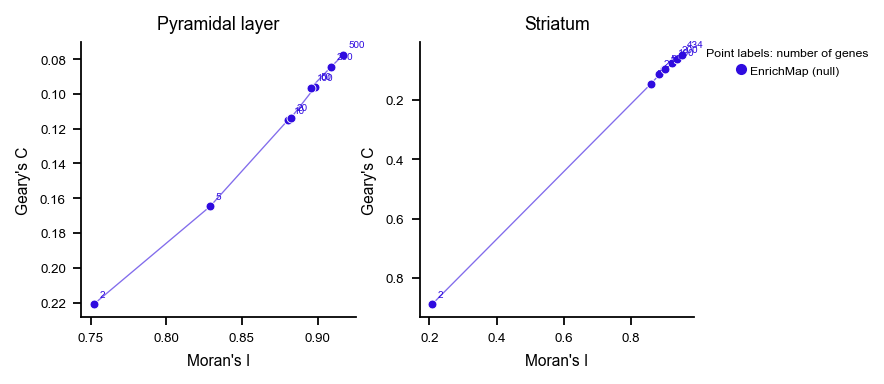

In [14]:
# 7. Sup. Fig. 5b-c: bars per statistic (full, as published) and Moran's I vs Geary's C (compact)
# fig = gss_bar_panel(autocorr, "Moran's I", "Moran's I (spatial coherence)", (0, 1), regions, sizes, methods, colours)
# set_box_ratio(fig)
# plt.savefig(figure_dir + "REV_SupFig5_6_7_S5b_morans_i_full.pdf", bbox_inches="tight")
# plt.show()
# autocorr[["region", "method", "gene set size", "Moran's I", "Moran's I z (normal)"]].to_csv(
#     source_dir + "REV_SupFig5_6_7_S5b_morans_i_full.csv", index=False
# )

# fig = gss_bar_panel(autocorr, "Geary's C", "Geary's C (local dissimilarity)",
#                     (0, max(0.4, autocorr["Geary's C"].max() * 1.05)), regions, sizes, methods, colours)
# set_box_ratio(fig)
# plt.savefig(figure_dir + "REV_SupFig5_6_7_S5c_gearys_c_full.pdf", bbox_inches="tight")
# plt.show()
# autocorr[["region", "method", "gene set size", "Geary's C", "Geary's C z (normal)"]].to_csv(
#     source_dir + "REV_SupFig5_6_7_S5c_gearys_c_full.csv", index=False
# )

# one filled circle per method and size, labelled with the number of genes
fig, axes = plt.subplots(1, 2, figsize=(5.4, 2.4))
for ax, ct in zip(axes, regions):
    gss_pair_panel(ax, autocorr[autocorr.region == ct], "Moran's I", "Geary's C", methods, colours, title=ct.replace("_", " "), invert_y=True)
    ax.set_box_aspect(1)
gss_method_legend(axes[1], methods, colours)
plt.tight_layout()
plt.savefig(figure_dir + "ExtendedDataFig4d_morans_i_vs_gearys_c.pdf", bbox_inches="tight")
plt.show()
autocorr[["region", "method", "gene set size", "Moran's I", "Geary's C"]].to_csv(
    source_dir + "ExtendedDataFig4d_morans_i_vs_gearys_c.csv", index=False
)

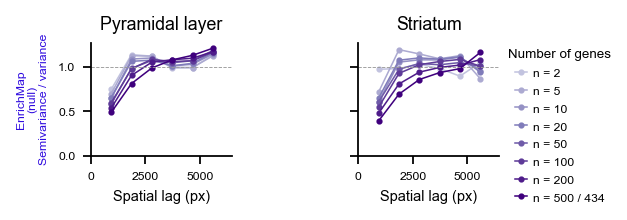

In [15]:
# 8. Sup. Fig. 5d: experimental variograms (skgstat, as em.pl.variogram_all; x axis cut at the 95th percentile)
max_lag = np.percentile(pdist(coords), 95)
summary_rows = []
for ct in regions:
    for m in methods:
        for n in sizes[ct]:
            values = scores[ct][m][n]
            V = Variogram(coords, values, method="cressie", model="gaussian", verbose=False)
            var = np.var(values)
            for lag, semivariance, count in zip(V.bins, V.experimental, V.bin_count):
                summary_rows.append({
                    "region": ct,
                    "method": m,
                    "gene set size": n,
                    "spatial lag (px, bin upper edge)": lag,
                    "semivariance": semivariance,
                    "n pairs": int(count),
                    "score variance (dashed line)": var,
                    "semivariance / variance": semivariance / var,
                    "within plotted x range": bool(lag <= max_lag),
                })
variograms = pd.DataFrame(summary_rows)

# gene set sizes as shades of purple (light = small, dark = large, as in the published panel)
size_shades = plt.get_cmap("Purples")(np.linspace(0.35, 1.0, 8))
SEMIVARIANCE_UNIT = {"EnrichMap (null)": "z²"}

for normalised, stem in [(True, "REV_SupFig5_6_7_S5d_variograms")]:
    fig = gss_draw_variograms(variograms, normalised, methods, regions, sizes, colours, size_shades, max_lag, ROW_LABEL, SEMIVARIANCE_UNIT)
    set_box_ratio(fig)
    plt.savefig(figure_dir + "ExtendedDataFig4e_variograms.pdf", bbox_inches="tight")
    plt.show()
    variograms.to_csv(source_dir + "ExtendedDataFig4e_variograms.csv", index=False)

metric                                   AUPRC            AUROC     F1 (optimal)
method                        EnrichMap (null) EnrichMap (null) EnrichMap (null)
region          gene set size                                                   
Pyramidal_layer 2                        0.480            0.990            0.621
                5                        0.515            0.991            0.626
                10                       0.631            0.994            0.737
                20                       0.682            0.996            0.753
                50                       0.705            0.996            0.766
                100                      0.733            0.996            0.774
                200                      0.716            0.996            0.784
                500                      0.779            0.997            0.804
Striatum        2                        0.404            0.691            0.542
                5           

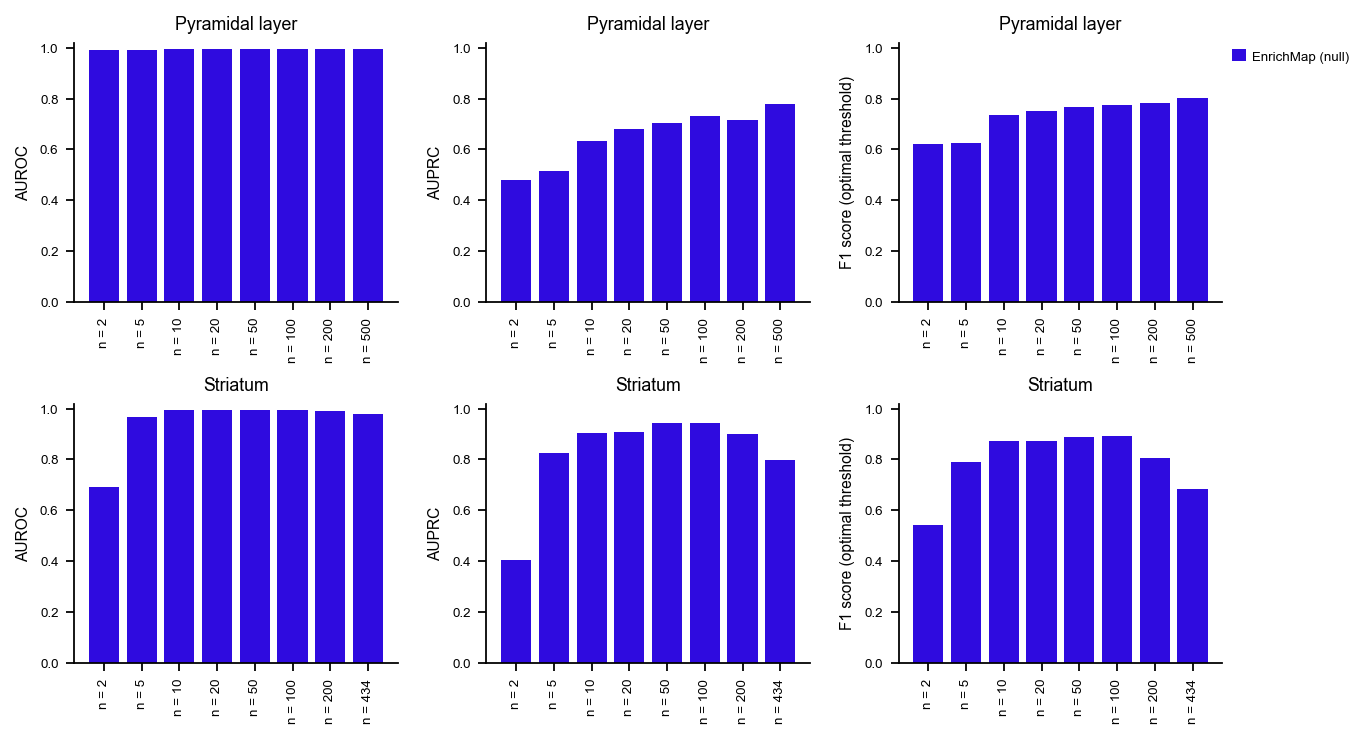

In [16]:
# 9. Sup. Fig. 5e: AUROC, AUPRC and F1 (optimal threshold) per size (em.tl.benchmark_scoring_methods)
clf = []
for ct in regions:
    for m, k in method_keys.items():
        keys = [k.format(name=f"{ct}_top{n}") for n in sizes[ct]]
        res = em.tl.benchmark_scoring_methods(adata, keys, label_source="cluster", positive_class=ct, plot=False)
        res["gene set size"] = res["method"].map(dict(zip(keys, sizes[ct])))
        res["region"], res["method"] = ct, m
        clf.append(res[["region", "method", "gene set size", "metric", "value"]])
clf = pd.concat(clf, ignore_index=True)
print(clf.pivot_table(index=["region", "gene set size"], columns=["metric", "method"], values="value").round(3).to_string())

metric_labels = {"AUROC": "AUROC", "AUPRC": "AUPRC", "F1 (optimal)": "F1 score (optimal threshold)"}
fig, axes = plt.subplots(2, 3, figsize=(8.6, 4.6))
for i, ct in enumerate(regions):
    for j, metric in enumerate(metric_labels):
        ax = axes[i, j]
        gss_grouped_bars(ax, clf[(clf.region == ct) & (clf.metric == metric)], "value", sizes[ct], methods, colours)
        ax.set_ylim(0, 1.02)
        ax.set_ylabel(metric_labels[metric], fontsize=7)
        ax.set_title(ct.replace("_", " "), fontsize=8)
axes[0, 2].legend(frameon=False, fontsize=6, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
set_box_ratio(fig)
plt.savefig(figure_dir + "REV_SupFig5_6_7_S5e_classification_full.pdf", bbox_inches="tight")
plt.show()


                                            hi                                lo                 
metric                                   AUPRC            AUROC            AUPRC            AUROC
method                        EnrichMap (null) EnrichMap (null) EnrichMap (null) EnrichMap (null)
region          gene set size                                                                    
Pyramidal_layer 2                        0.579            0.996            0.384            0.984
                5                        0.618            0.996            0.388            0.986
                10                       0.789            0.998            0.463            0.990
                20                       0.848            0.998            0.488            0.992
                50                       0.881            0.999            0.531            0.993
                100                      0.895            0.999            0.543            0.993
                200 

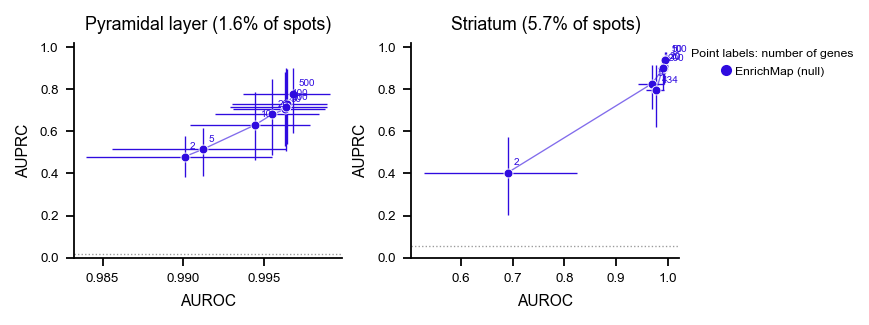

In [17]:
# 10. Paired spatial block bootstrap of AUROC and AUPRC (150 k-means blocks, seed 1; 1,000 replicates, seed 7)
blocks = gss_spatial_folds(coords, n_blocks=150, n_folds=150, seed=1)
boot = pd.concat([
    gss_paired_block_bootstrap(labels[ct], {(m, n): scores[ct][m][n] for m in methods for n in sizes[ct]}, blocks)
    .assign(region=ct)
    for ct in regions
], ignore_index=True)

ci = (boot.groupby(["region", "method", "gene set size", "metric"])["value"]
      .agg(lo=lambda v: np.quantile(v, 0.025), hi=lambda v: np.quantile(v, 0.975), n_replicates="size")
      .reset_index())
auc_table = clf[clf.metric.isin(["AUROC", "AUPRC"])].merge(ci, on=["region", "method", "gene set size", "metric"])
print(auc_table.pivot_table(index=["region", "gene set size"], columns=["metric", "method"], values=["lo", "hi"])
      .round(3).to_string())

# one filled circle per method and size (95% interval whiskers), labelled with the number of genes
fig, axes = plt.subplots(1, 2, figsize=(5.4, 2.5))
for ax, ct in zip(axes, regions):
    gss_pair_panel(ax, gss_wide_auc(auc_table, ct), "AUROC", "AUPRC", methods, colours, ref_y=prevalence[ct])
    ax.set_title(f"{ct.replace('_', ' ')} ({100 * prevalence[ct]:.1f}% of spots)", fontsize=8)
    ax.set_ylim(0, 1.02)
gss_method_legend(axes[1], methods, colours)
plt.tight_layout()
set_box_ratio(fig)
plt.savefig(figure_dir + "ExtendedDataFig4g_auroc_vs_auprc.pdf", bbox_inches="tight")
plt.show()
auc_table.to_csv(source_dir + "ExtendedDataFig4g_auroc_vs_auprc.csv", index=False)


In [18]:
# 11. Sup. Fig. 5e (threshold rules): oracle and label-free rules for every method, fixed rules of the null model
RULES = ["Oracle", "Top-k", "Otsu", "Median", "z > 0", "z > 1.96", "p_emp ≤ 0.05"]

summary_rows = []
for ct in regions:
    y = labels[ct]
    for m in methods:
        for n in sizes[ct]:
            s = scores[ct][m][n]
            f1_opt = clf[(clf.region == ct) & (clf.method == m) & (clf["gene set size"] == n)
                         & (clf.metric == "F1 (optimal)")]["value"].item()
            calls = {"Top-k": gss_topk_calls(y, s), "Otsu": s > gss_otsu_threshold(s), "Median": s > np.median(s)}
            if m == "EnrichMap (null)":
                calls.update({"z > 0": s > 0, "z > 1.96": s > 1.96, "p_emp ≤ 0.05": p_empirical[ct][n] <= 0.05})
            summary_rows.append({
                "region": ct, "method": m, "gene set size": n, "rule": "Oracle", "F1": f1_opt,
                "precision": np.nan, "recall": np.nan, "fraction of spots called": np.nan,
            })
            for rule, pred in calls.items():
                summary_rows.append({
                    "region": ct, "method": m, "gene set size": n, "rule": rule,
                    "F1": f1_score(y, pred, zero_division=0), "precision": precision_score(y, pred, zero_division=0),
                    "recall": recall_score(y, pred), "fraction of spots called": pred.mean(),
                })
thresholds = pd.DataFrame(summary_rows)
print(thresholds.pivot_table(index=["region", "gene set size"], columns=["rule", "method"], values="F1")
      .round(3).T.to_string())

region                        Pyramidal_layer                                                  Striatum                                                 
gene set size                             2      5      10     20     50     100    200    500      2      5      10     20     50     100    200    434
rule         method                                                                                                                                     
Median       EnrichMap (null)           0.061  0.061  0.061  0.061  0.061  0.061  0.061  0.061    0.134  0.200  0.204  0.204  0.204  0.204  0.204  0.204
Oracle       EnrichMap (null)           0.621  0.626  0.737  0.753  0.766  0.774  0.784  0.804    0.542  0.789  0.873  0.871  0.890  0.893  0.807  0.683
Otsu         EnrichMap (null)           0.543  0.577  0.515  0.553  0.480  0.515  0.424  0.058    0.013  0.734  0.840  0.855  0.873  0.820  0.671  0.548
Top-k        EnrichMap (null)           0.500  0.548  0.619  0.667  0.690  0.690  

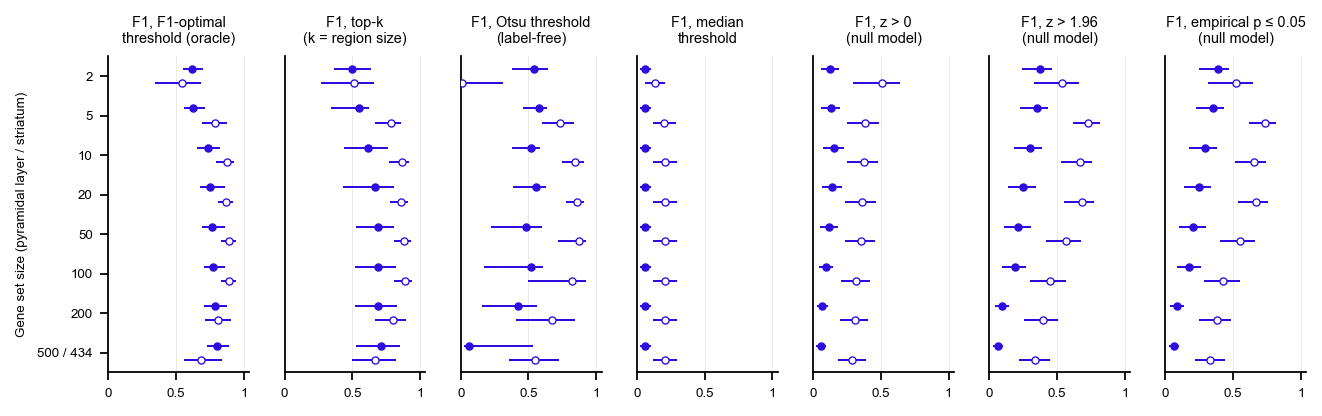

rule                                     Oracle             Top-k              Otsu            Median             z > 0          z > 1.96      p_emp ≤ 0.05
region          gene set size                                                                                                                              
Pyramidal_layer 2              0.62 (0.55-0.70)  0.50 (0.36-0.64)  0.54 (0.38-0.64)  0.06 (0.02-0.10)  0.13 (0.06-0.19)  0.38 (0.24-0.46)  0.39 (0.25-0.47)
                5              0.63 (0.56-0.71)  0.55 (0.35-0.62)  0.58 (0.46-0.64)  0.06 (0.02-0.10)  0.13 (0.06-0.20)  0.35 (0.23-0.43)  0.35 (0.22-0.43)
                10             0.74 (0.66-0.82)  0.62 (0.44-0.77)  0.52 (0.38-0.59)  0.06 (0.02-0.10)  0.15 (0.07-0.23)  0.30 (0.18-0.39)  0.29 (0.18-0.38)
                20             0.75 (0.68-0.86)  0.67 (0.43-0.81)  0.55 (0.38-0.63)  0.06 (0.02-0.10)  0.14 (0.07-0.21)  0.25 (0.14-0.34)  0.24 (0.14-0.33)
                50             0.77 (0.69-0.86)  0.69 (0.53-0.81

In [19]:
# # 12. Sup. Fig. 5e (threshold rules) figures: compact (shared rules as a summary, fixed rules next to the oracle F1)
# #     and full (F1 against gene set size for every method and rule)
SHARED_RULES = ["Oracle", "Top-k", "Otsu", "Median"]
FIXED_RULES = [
    ("EnrichMap (null)", "z > 0"),
    ("EnrichMap (null)", "z > 1.96"),
    ("EnrichMap (null)", "p_emp ≤ 0.05"),
]
FIXED_LABELS = {
    "z > 0": "null model: z > 0",
    "z > 1.96": "null model: z > 1.96",
    "p_emp ≤ 0.05": "null model: p_emp ≤ 0.05",
}
rule_means = thresholds.groupby(["region", "method", "rule"])["F1"].agg(["mean", "min", "max", "count"]).reset_index()
rule_tables = {
    ct: rule_means[rule_means.region == ct]
    .pivot_table(index="method", columns="rule", values="mean")
    .reindex(index=methods, columns=SHARED_RULES)
    for ct in regions
}

# fig = plt.figure(figsize=(7.4, 3.9))
# gs = fig.add_gridspec(2, 2, height_ratios=[1.6, 1.0], hspace=0.75, wspace=0.9)
# for j, ct in enumerate(regions):
#     ax = fig.add_subplot(gs[0, j])
#     gss_plot_summary(rule_tables[ct], ax, colours)
#     ax.set_title(f"{ct.replace('_', ' ')}: F1 by threshold rule", fontsize=8, pad=12)
#     ax.tick_params(labelsize=6)
#     gss_fixed_rules_axis(fig.add_subplot(gs[1, j]), rule_means, ct, FIXED_RULES, FIXED_LABELS, colours)
# set_box_ratio(fig)
# plt.savefig(figure_dir + "REV_SupFig5_6_7_S5e_threshold_rules.pdf", bbox_inches="tight")
# plt.show()
# rule_means.to_csv(source_dir + "REV_SupFig5_6_7_S5e_threshold_rules.csv", index=False)
# print(rule_means.pivot_table(index=["region", "method"], columns="rule", values="mean").round(3).to_string())

# full (EnrichMap (null), as Extended Data Fig. 2d): one column per rule, one row per gene set size, estimate and 95%
# interval from the spatial block bootstrap of section 10 (filled: pyramidal layer, open: striatum)
RULE_TITLES = {
    "Oracle": "F1, F1-optimal\nthreshold (oracle)",
    "Top-k": "F1, top-k\n(k = region size)",
    "Otsu": "F1, Otsu threshold\n(label-free)",
    "Median": "F1, median\nthreshold",
    "z > 0": "F1, z > 0\n(null model)",
    "z > 1.96": "F1, z > 1.96\n(null model)",
    "p_emp ≤ 0.05": "F1, empirical p ≤ 0.05\n(null model)",
}
NULL = "EnrichMap (null)"
rule_boot = pd.concat([
    gss_threshold_rule_bootstrap(labels[ct], scores[ct][NULL][n], p_empirical[ct][n], blocks)
    .assign(region=ct, **{"gene set size": n})
    for ct in regions for n in sizes[ct]
], ignore_index=True)
rule_ci = (rule_boot.groupby(["region", "gene set size", "rule"])["F1"]
           .agg(lo=lambda v: np.quantile(v, 0.025), hi=lambda v: np.quantile(v, 0.975), n_rep="size")
           .reset_index())
rule_plot = thresholds[thresholds.method == NULL].merge(rule_ci, on=["region", "gene set size", "rule"])

n_rows = len(sizes[regions[0]])
row_labels = [str(a) if a == b else f"{a} / {b}" for a, b in zip(sizes[regions[0]], sizes[regions[1]])]
fig, axes = plt.subplots(1, len(RULES), figsize=(9.6, 2.6))
for j, (ax, rule) in enumerate(zip(axes, RULES)):
    for i, ct in enumerate(regions):
        d = rule_plot[(rule_plot.region == ct) & (rule_plot.rule == rule)].set_index("gene set size").reindex(sizes[ct])
        for k, n in enumerate(sizes[ct]):
            y = k + (0.18 if i else -0.18)
            ax.plot([d.loc[n, "lo"], d.loc[n, "hi"]], [y, y], color=colours[NULL], lw=0.9, solid_capstyle="butt")
            ax.plot(d.loc[n, "F1"], y, "o", ms=3.2, color=colours[NULL], mfc="white" if i else colours[NULL], mew=0.6, zorder=3)
    format_benchmark_metric_axis(ax, "F1", n_rows)
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels(row_labels if j == 0 else [], fontsize=6)
    if j:
        ax.tick_params(axis="y", length=0)
    ax.set_title(RULE_TITLES[rule], fontsize=6.5)
axes[0].set_ylabel("Gene set size (pyramidal layer / striatum)", fontsize=6)
fig.subplots_adjust(wspace=0.25)
plt.savefig(figure_dir + "ExtendedDataFig4h_threshold_rules.pdf", bbox_inches="tight")
plt.show()
rule_plot.rename(columns={"F1": "estimate", "lo": "95% CI lo", "hi": "95% CI hi", "n_rep": "n replicates"}).to_csv(
    source_dir + "ExtendedDataFig4h_threshold_rules.csv", index=False
)
print(rule_plot.assign(txt=lambda d: d.apply(lambda r: f"{r.F1:.2f} ({r.lo:.2f}-{r.hi:.2f})", axis=1))
      .pivot_table(index=["region", "gene set size"], columns="rule", values="txt", aggfunc="first")[RULES].to_string())


In [20]:
# 13. Sup. Fig. 6a-b: score at each size against the spatial lag of the n = 50 score of the same method
# as em.pl.cross_moran_scatter: libpysal KNN k = 6, row-standardised; quadrants at 0 (library_key=None)
W6 = KNN.from_array(coords, k=6)
W6.transform = "r"
quadrant_names = {"HH": "Co-enriched", "LL": "Co-depleted", "HL": "Discordant", "LH": "Discordant"}
cm_points, cm_stats = {ct: [] for ct in regions}, []
for ct in regions:
    for m in methods:
        y_lag = lag_spatial(W6, scores[ct][m][50])
        for n in sizes[ct]:
            x = scores[ct][m][n]
            r, p = pearsonr(x, y_lag)
            quadrants = np.full(len(x), "LL", dtype=object)
            quadrants[(x >= 0) & (y_lag >= 0)] = "HH"
            quadrants[(x >= 0) & (y_lag < 0)] = "HL"
            quadrants[(x < 0) & (y_lag >= 0)] = "LH"
            slope, intercept = np.polyfit(x, y_lag, 1)
            cm_points[ct].append(pd.DataFrame({
                "spot_id": adata.obs_names, "method": m, "gene set size": n, "score": x,
                "spatial lag of n = 50 score": y_lag, "quadrant": [quadrant_names[q] for q in quadrants],
            }))
            cm_stats.append({
                "region": ct, "method": m, "gene set size": n, "pearson r": r, "p value": p,
                "log10 p": gss_log10_p(r, len(x)), "n spots": len(x), "ols slope": slope, "ols intercept": intercept,
                "n co-enriched": int((quadrants == "HH").sum()), "n co-depleted": int((quadrants == "LL").sum()),
                "n discordant": int(np.isin(quadrants, ["HL", "LH"]).sum()),
            })
    cm_points[ct] = pd.concat(cm_points[ct], ignore_index=True)
cm_stats = pd.DataFrame(cm_stats)
print(cm_stats.pivot_table(index=["region", "gene set size"], columns="method", values="pearson r").round(3).to_string())

method                         EnrichMap (null)
region          gene set size                  
Pyramidal_layer 2                         0.820
                5                         0.856
                10                        0.935
                20                        0.943
                50                        0.976
                100                       0.965
                200                       0.937
                500                       0.863
Striatum        2                         0.269
                5                         0.832
                10                        0.928
                20                        0.923
                50                        0.978
                100                       0.961
                200                       0.939
                434                       0.882


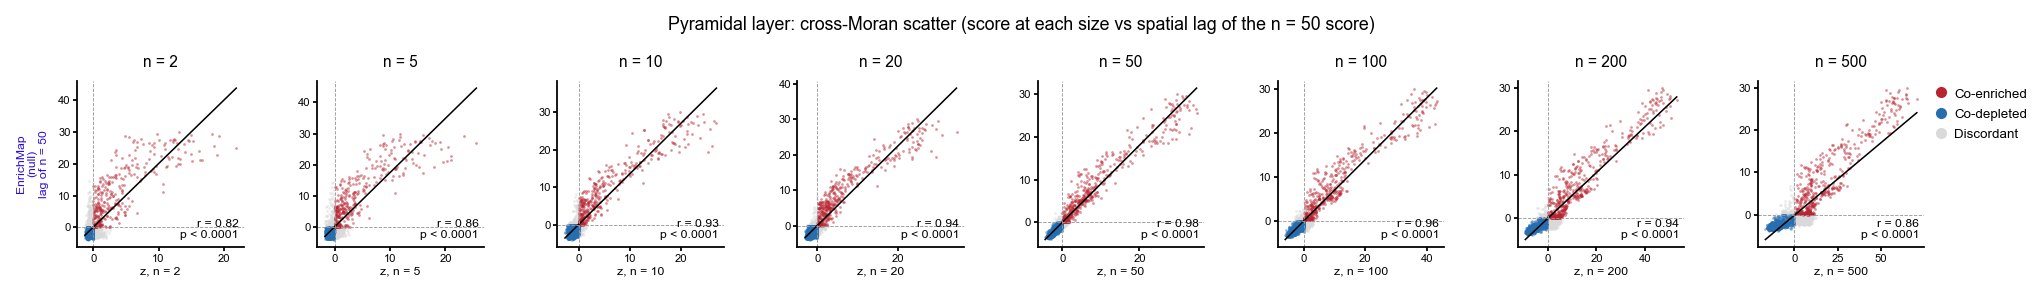

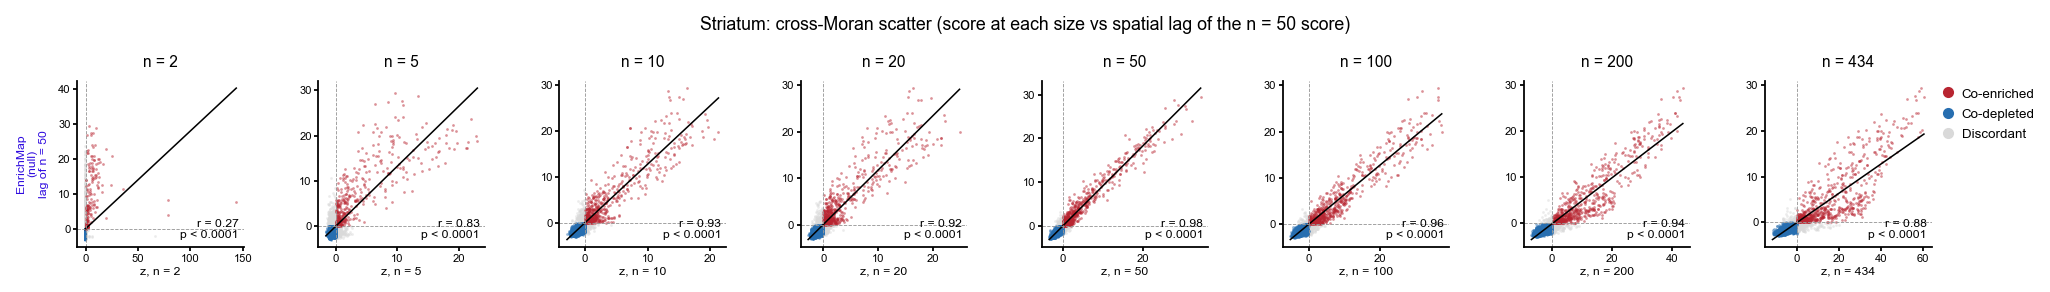

In [21]:
# quadrant colours: the two ends of RdBu_r and grey
cmap = mpl.colormaps["RdBu_r"]
QUADRANT_COLOURS = {"Discordant": "#d9d9d9", "Co-depleted": cmap(0.12), "Co-enriched": cmap(0.88)}
AXIS_UNIT = {"EnrichMap (null)": "z"}

for label, ct in [("S6a", cell_type_1), ("S6b", cell_type_2)]:
    stem = f"REV_SupFig5_6_7_{label}_cross_moran_{ct.lower()}"
    fig = gss_draw_cross_moran(cm_points[ct], cm_stats, ct, methods, sizes[ct], colours, QUADRANT_COLOURS, AXIS_UNIT, ROW_LABEL)
    set_box_ratio(fig, ratio=1)
    plt.savefig(figure_dir + f"ExtendedDataFig5a_cross_moran_{ct.lower()}.pdf", bbox_inches="tight")
    plt.show()
    cm_points[ct].merge(cm_stats[cm_stats.region == ct].drop(columns="region"), on=["method", "gene set size"]).to_csv(
        source_dir + f"ExtendedDataFig5a_cross_moran_{ct.lower()}.csv", index=False
    )

method                         EnrichMap (null)
region          gene set size                  
Pyramidal_layer 2                        0.3467
                5                        0.4420
                10                       0.6855
                20                       0.7548
                100                      0.9070
                200                      0.8736
                500                      0.8172
Striatum        2                       -0.0202
                5                        0.4784
                10                       0.7795
                20                       0.8233
                100                      0.8421
                200                      0.8214
                434                      0.7768


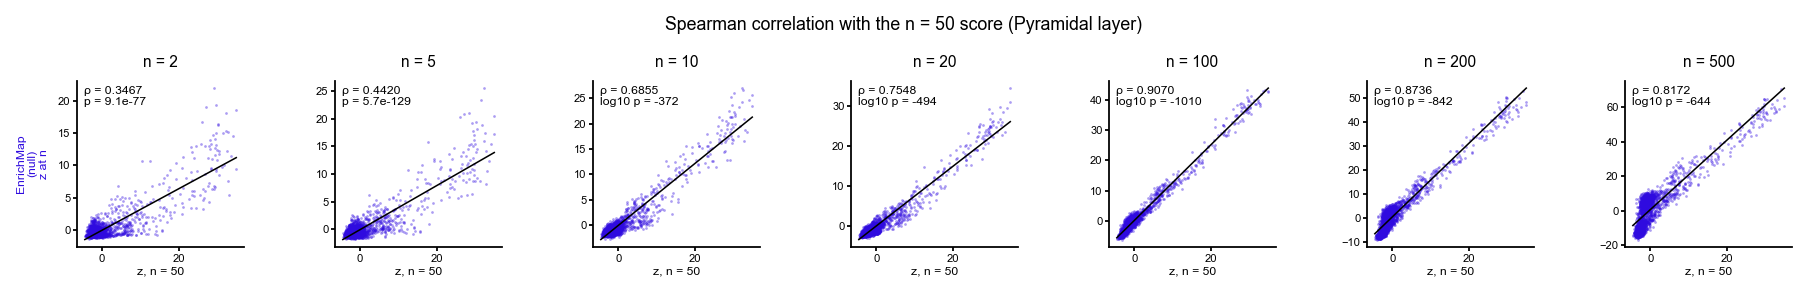

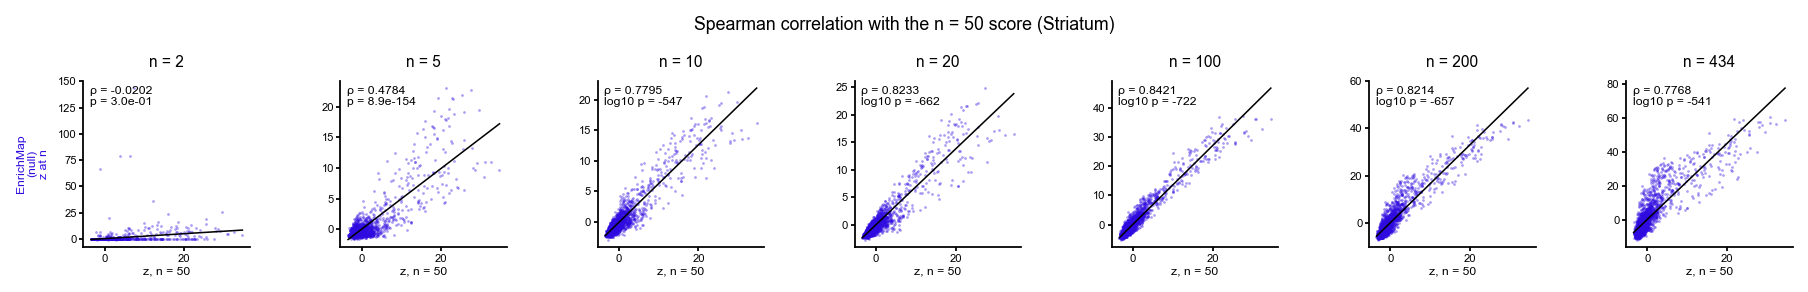

In [22]:
# 14. Sup. Fig. 6c-d: spot-level Spearman correlation with the n = 50 score of the same method
sp_points, sp_stats = {ct: [] for ct in regions}, []
for ct in regions:
    for m in methods:
        x = scores[ct][m][50]
        for n in [k for k in sizes[ct] if k != 50]:
            y = scores[ct][m][n]
            rho, p = spearmanr(x, y)
            slope, intercept = np.polyfit(x, y, 1)
            sp_points[ct].append(pd.DataFrame({
                "spot_id": adata.obs_names, "method": m, "gene set size": n, "score n = 50": x, "score n": y,
            }))
            sp_stats.append({
                "region": ct, "method": m, "gene set size": n, "spearman rho": rho, "p value": p,
                "log10 p": gss_log10_p(rho, len(x)), "n spots": len(x), "ols slope": slope, "ols intercept": intercept,
            })
    sp_points[ct] = pd.concat(sp_points[ct], ignore_index=True)
sp_stats = pd.DataFrame(sp_stats)
print(sp_stats.pivot_table(index=["region", "gene set size"], columns="method", values="spearman rho").round(4).to_string())

for label, ct in [("S6c", cell_type_1), ("S6d", cell_type_2)]:
    stem = f"REV_SupFig5_6_7_{label}_spearman_{ct.lower()}"
    fig = gss_draw_spearman(sp_points[ct], sp_stats, ct, methods, sizes[ct], colours, AXIS_UNIT, ROW_LABEL)
    set_box_ratio(fig, ratio=1)
    plt.savefig(figure_dir + f"ExtendedDataFig5b_spearman_{ct.lower()}.pdf", bbox_inches="tight")
    plt.show()
    sp_points[ct].merge(sp_stats[sp_stats.region == ct].drop(columns="region"), on=["method", "gene set size"]).to_csv(
        source_dir + f"ExtendedDataFig5b_spearman_{ct.lower()}.csv", index=False
    )

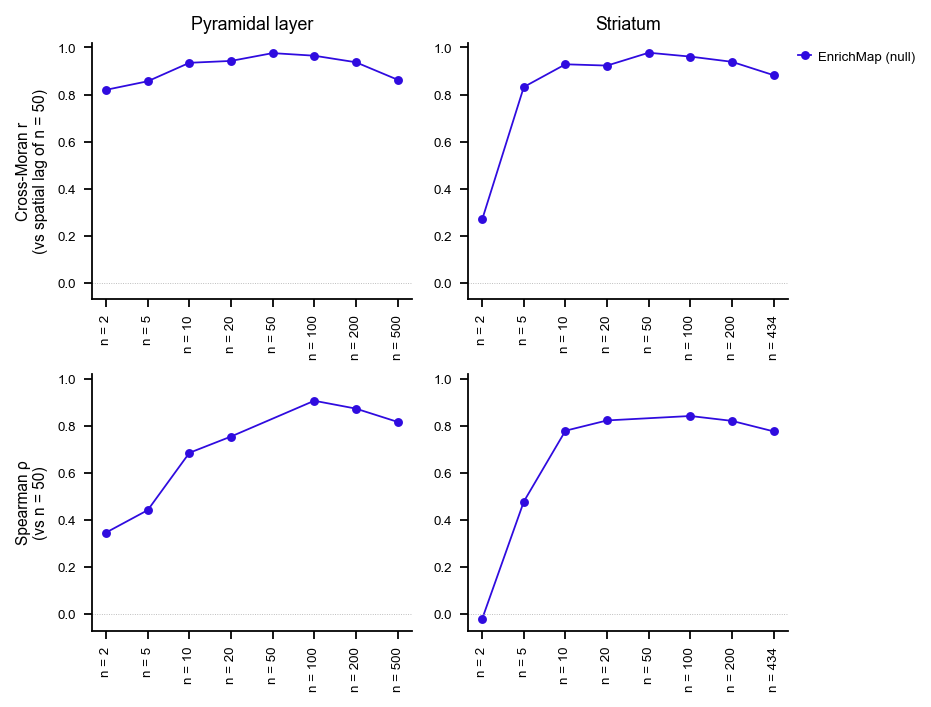

In [23]:
# 15. Sup. Fig. 6a-d compact: cross-Moran r and Spearman rho against gene set size, per method
fig, axes = plt.subplots(2, 2, figsize=(5.8, 4.4))
for j, ct in enumerate(regions):
    for m in methods:
        d = cm_stats[(cm_stats.region == ct) & (cm_stats.method == m)].sort_values("gene set size")
        axes[0, j].plot(np.arange(len(d)), d["pearson r"], "o-", ms=3, lw=0.8, color=colours[m], label=m)
        d = sp_stats[(sp_stats.region == ct) & (sp_stats.method == m)].sort_values("gene set size")
        x = [sizes[ct].index(n) for n in d["gene set size"]]
        axes[1, j].plot(x, d["spearman rho"], "o-", ms=3, lw=0.8, color=colours[m], label=m)
    for i in range(2):
        ax = axes[i, j]
        ax.set_xticks(np.arange(len(sizes[ct])))
        ax.set_xticklabels(gss_size_ticks(sizes[ct]), rotation=90, fontsize=6)
        ax.set_ylim(min(0.0, sp_stats["spearman rho"].min() - 0.05, cm_stats["pearson r"].min() - 0.05), 1.02)
        ax.axhline(0, color="0.7", lw=0.4, ls=":")
        ax.tick_params(axis="y", labelsize=6)
        ax.grid(False)
        sns.despine(ax=ax)
    axes[0, j].set_title(ct.replace("_", " "), fontsize=8)
axes[0, 0].set_ylabel("Cross-Moran r\n(vs spatial lag of n = 50)", fontsize=7)
axes[1, 0].set_ylabel("Spearman ρ\n(vs n = 50)", fontsize=7)
axes[0, 1].legend(frameon=False, fontsize=6, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
set_box_ratio(fig)
plt.savefig(figure_dir + "ExtendedDataFig4f_correlation_summary.pdf", bbox_inches="tight")
plt.show()
correlation_summary = cm_stats[["region", "method", "gene set size", "pearson r"]].merge(
    sp_stats[["region", "method", "gene set size", "spearman rho"]], on=["region", "method", "gene set size"], how="left"
)
correlation_summary.to_csv(source_dir + "ExtendedDataFig4f_correlation_summary.csv", index=False)

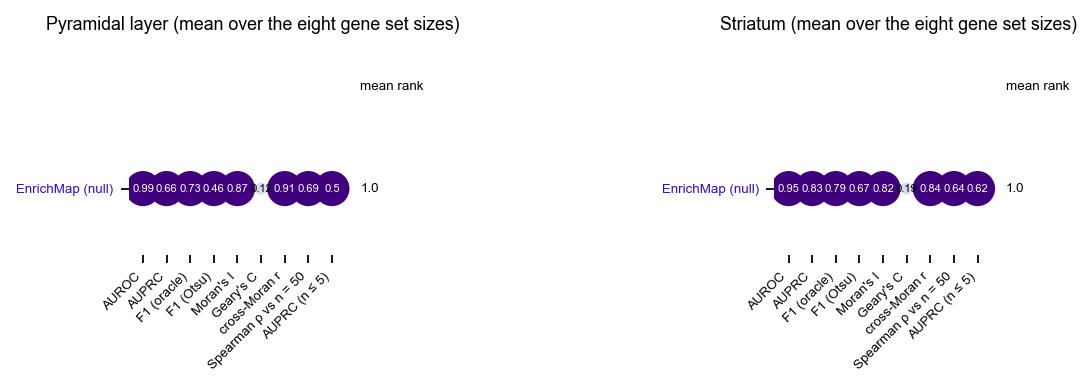

          method  AUROC  AUPRC  F1 (oracle)  F1 (Otsu)  Moran's I  Geary's C  cross-Moran r  Spearman ρ vs n = 50  AUPRC (n ≤ 5)          region
EnrichMap (null)  0.995  0.655        0.733      0.458       0.87      0.121          0.912                 0.690          0.497 Pyramidal_layer
EnrichMap (null)  0.950  0.828        0.793      0.669       0.82      0.191          0.839                 0.643          0.615        Striatum


In [24]:
# 16. Benchmark summary: methods x key metrics of Sup. Figs. 5b-e and 6a-d, mean over the gene set sizes
summary_tables = {}
for ct in regions:
    c = clf[clf.region == ct].pivot_table(index="method", columns="metric", values="value", aggfunc="mean")
    a = autocorr[autocorr.region == ct].groupby("method")[["Moran's I", "Geary's C"]].mean()
    summary_tables[ct] = pd.DataFrame({
        "AUROC": c["AUROC"],
        "AUPRC": c["AUPRC"],
        "F1 (oracle)": c["F1 (optimal)"],
        "F1 (Otsu)": rule_tables[ct]["Otsu"],
        "Moran's I": a["Moran's I"],
        "Geary's C": a["Geary's C"],
        "cross-Moran r": cm_stats[cm_stats.region == ct].groupby("method")["pearson r"].mean(),
        "Spearman ρ vs n = 50": sp_stats[sp_stats.region == ct].groupby("method")["spearman rho"].mean(),
        "AUPRC (n ≤ 5)": clf[(clf.region == ct) & (clf.metric == "AUPRC") & (clf["gene set size"] <= 5)]
        .groupby("method")["value"].mean(),
    }).reindex(methods)

fig, axes = plt.subplots(1, 2, figsize=(8.0, 2.4))
for ax, ct in zip(axes, regions):
    gss_plot_summary(summary_tables[ct], ax, colours, lower_is_better=("Geary's C",))
    ax.set_title(f"{ct.replace('_', ' ')} (mean over the eight gene set sizes)", fontsize=8, pad=12)
    ax.tick_params(labelsize=6)
plt.tight_layout(w_pad=3)
set_box_ratio(fig)
plt.savefig(figure_dir + "REV_SupFig5_6_7_S5_S6_summary.pdf", bbox_inches="tight")
plt.show()
bench_summary = pd.concat(
    [summary_tables[ct].assign(region=ct).reset_index() for ct in regions], ignore_index=True,
)

print(bench_summary.round(3).to_string(index=False))

In [25]:
# 17. Sup. Fig. 6e: MSigDB gene set sizes (19_gene_set_sizes)
ANNOTATIONS_URL = "https://omnipathdb.org/annotations"

raw = gss_fetch_msigdb(ANNOTATIONS_URL)
parsed = gss_parse_msigdb(raw)
summary = gss_msigdb_gene_set_sizes(parsed)

# remove irrelevant collections
summary = summary[
    ~summary["collection"].isin(
        [
            "chemical_and_genetic_perturbations",
            "human_phenotype_ontology",
            "cancer_gene_neighborhoods",
            "cancer_modules",
            "cancer_cell_atlas",
            "vaccine_response",
            "tf_targets_gtrf",
            "tf_targets_legacy",
            "positional",
            "pid_pathways",
            "cell_type_signatures",
        ]
    )
]

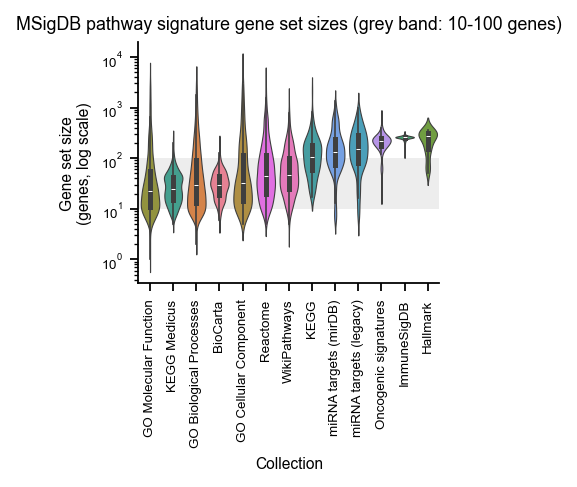

In [26]:
# order by median; collection colours as in 19_gene_set_sizes (husl palette over the alphabetical collection order)
order = summary.groupby("collection")["gene_set_size"].median().sort_values().index
display_name = {
    "go_molecular_function": "GO Molecular Function", "kegg_medicus_pathways": "KEGG Medicus",
    "go_biological_process": "GO Biological Processes", "biocarta_pathways": "BioCarta",
    "go_cellular_component": "GO Cellular Component", "reactome_pathways": "Reactome",
    "wikipathways": "WikiPathways", "kegg_pathways": "KEGG", "mirna_targets_mirdb": "miRNA targets (mirDB)",
    "mirna_targets_legacy": "miRNA targets (legacy)", "oncogenic_signatures": "Oncogenic signatures",
    "immunesigdb": "ImmuneSigDB", "hallmark": "Hallmark",
}
hue_order = sorted(summary["collection"].unique())

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.axhspan(10, 100, color="0.93", lw=0, zorder=0)
sns.violinplot(
    data=summary,
    x="collection",
    y="gene_set_size",
    inner="box",
    order=order,
    log_scale=True,
    hue="collection",
    hue_order=hue_order,
    palette=sns.color_palette("husl", len(hue_order)),
    linewidth=0.5,
    legend=False,
    ax=ax,
)
ax.set_xticks(np.arange(len(order)))
ax.set_xticklabels([display_name.get(c, c) for c in order], rotation=90, fontsize=6)
ax.set_xlabel("Collection", fontsize=7)
ax.set_ylabel("Gene set size\n(genes, log scale)", fontsize=7)
ax.set_title("MSigDB pathway signature gene set sizes (grey band: 10-100 genes)", fontsize=8)
ax.tick_params(axis="y", labelsize=6)
ax.grid(False)
sns.despine(ax=ax)
plt.tight_layout()
set_box_ratio(fig)
plt.savefig(figure_dir + "ExtendedDataFig5c_msigdb_gene_set_sizes.pdf", bbox_inches="tight")
plt.show()

msigdb = summary.assign(
    x_order=summary["collection"].map({c: i + 1 for i, c in enumerate(order)}),
    collection_label=summary["collection"].map(lambda c: display_name.get(c, c)),
).sort_values(["x_order", "gene_set_size"])
msigdb[["x_order", "collection_label", "collection", "geneset", "gene_set_size"]].to_csv(
    source_dir + "ExtendedDataFig5c_msigdb_gene_set_sizes.csv", index=False
)